In [1]:
import io
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import os

filename = "coimbatore_oct2026.csv"

url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": 11.0168,
    "longitude": 76.9558,
    "start_date": "2026-10-01",
    "end_date": "2026-10-31",
    "daily": ",".join([
        "temperature_2m_max", "temperature_2m_min", "temperature_2m_mean",
        "apparent_temperature_max", "precipitation_sum",
        "wind_speed_10m_max", "wind_gusts_10m_max", "shortwave_radiation_sum",
    ]),
    "timezone": "Asia/Kolkata",
    "format": "csv",
}

if os.path.exists(filename):
    print(f"Using existing file: {filename}")
else:
    response = requests.get(url, params=params, timeout=30)
    if response.status_code != 200:
        print("Download failed:", response.status_code)
        print(response.text[:500])
    else:
        with open(filename, "w", encoding="utf-8") as f:
            f.write(response.text)
        print(f"Saved {filename}")

Using existing file: coimbatore_oct2026.csv


In [3]:
with open("coimbatore_oct2026.csv", encoding="utf-8") as f:
    lines = f.read().splitlines()

# Find the line where the real table starts (it begins with "time,")
start = [i for i, line in enumerate(lines) if line.startswith("time,")][0]
df = pd.read_csv(io.StringIO("\n".join(lines[start:])))

# Remove units like "(°C)" from column names, then give friendly names
df.columns = [c.split(" (")[0] for c in df.columns]
df = df.rename(columns={
    "time": "Date",
    "temperature_2m_max": "Max_Temp",
    "temperature_2m_min": "Min_Temp",
    "temperature_2m_mean": "Avg_Temp",
    "apparent_temperature_max": "Feels_Like_Max",
    "precipitation_sum": "Rain_mm",
    "wind_speed_10m_max": "Wind_Max",
    "wind_gusts_10m_max": "Gust_Max",
    "shortwave_radiation_sum": "Solar_Radiation",
})

df["Date"] = pd.to_datetime(df["Date"])

print("Rows, columns:", df.shape)               # expect 31 rows
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

df = df.dropna().drop_duplicates().reset_index(drop=True)
df["Range"] = df["Max_Temp"] - df["Min_Temp"]
df.head()

Rows, columns: (31, 9)
Missing values: 0
Duplicate rows: 0


,Date,Max_Temp,Min_Temp,Avg_Temp,Feels_Like_Max,Rain_mm,Wind_Max,Gust_Max,Solar_Radiation,Range
0,2026-10-01,35.5,25.1,28.1,39.0,7.6,19.9,49.0,20.60,10.4
1,2026-10-02,33.8,24.9,29.0,36.1,0.6,16.1,42.5,23.80,8.9
2,2026-10-03,34.0,23.3,28.3,36.6,1.7,14.1,34.2,22.47,10.7
3,2026-10-04,35.3,24.6,28.1,38.7,6.2,17.5,39.2,21.03,10.7
4,2026-10-05,34.5,23.4,27.6,38.0,1.5,13.1,43.2,17.67,11.1


In [4]:
checks = []
def check(name, condition):
    checks.append((name, bool(condition)))
    print(("PASS  " if condition else "FAIL  ") + name)

check("31 rows (October has 31 days)", len(df) == 31)
check("No missing values", df.isnull().sum().sum() == 0)
check("No duplicate dates", df["Date"].is_unique)
check("Dates are consecutive (no gaps)", (df["Date"].diff().dropna() == pd.Timedelta(days=1)).all())
check("Max_Temp is always >= Min_Temp", (df["Max_Temp"] >= df["Min_Temp"]).all())
check("Avg_Temp lies between Min and Max", ((df["Avg_Temp"] >= df["Min_Temp"]) & (df["Avg_Temp"] <= df["Max_Temp"])).all())
check("Temperatures are realistic (10 to 45 °C)", df[["Max_Temp","Min_Temp"]].stack().between(10,45).all())
check("Rainfall is never negative", (df["Rain_mm"] >= 0).all())
check("Wind gust >= wind speed", (df["Gust_Max"] >= df["Wind_Max"]).all())

print("\nAll checks passed!" if all(c for _, c in checks) else "\nSome checks FAILED - read the FAIL lines above.")

PASS  31 rows (October has 31 days)
PASS  No missing values
PASS  No duplicate dates
PASS  Dates are consecutive (no gaps)
PASS  Max_Temp is always >= Min_Temp
PASS  Avg_Temp lies between Min and Max
PASS  Temperatures are realistic (10 to 45 °C)
PASS  Rainfall is never negative
PASS  Wind gust >= wind speed

All checks passed!


In [5]:
highest = df["Max_Temp"].max()
lowest  = df["Min_Temp"].min()
average = df["Avg_Temp"].mean()

hottest = df.loc[df["Max_Temp"] == highest, "Date"].dt.date.tolist()
coolest = df.loc[df["Min_Temp"] == lowest,  "Date"].dt.date.tolist()

print("===== TEMPERATURE RESULTS =====")
print(f"Maximum Temperature : {highest:.1f} °C on {hottest}")
print(f"Minimum Temperature : {lowest:.1f} °C on {coolest}")
print(f"Average Temperature : {average:.1f} °C")
print(f"Average daily range : {df['Range'].mean():.1f} °C")
print(f"Day with biggest range: {df.loc[df['Range'].idxmax(), 'Date'].date()}")

# Summary table of every numeric column
df.describe().round(2)

===== TEMPERATURE RESULTS =====
Maximum Temperature : 35.5 °C on [datetime.date(2026, 10, 1), datetime.date(2026, 10, 15)]
Minimum Temperature : 21.5 °C on [datetime.date(2026, 10, 29)]
Average Temperature : 26.9 °C
Average daily range : 8.5 °C
Day with biggest range: 2026-10-15


,Date,Max_Temp,Min_Temp,Avg_Temp,Feels_Like_Max,Rain_mm,Wind_Max,Gust_Max,Solar_Radiation,Range
count,31,31.00,31.00,31.00,31.00,31.00,31.00,31.00,31.00,31.00
mean,2026-10-16 00:00:00,31.81,23.28,26.90,35.30,7.93,13.81,34.92,20.04,8.53
min,2026-10-01 00:00:00,26.80,21.50,24.30,31.00,0.00,6.70,18.70,8.59,4.00
25%,2026-10-08 12:00:00,29.65,22.70,25.65,34.00,0.30,11.30,30.05,18.09,6.80
50%,2026-10-16 00:00:00,31.70,23.20,26.90,35.00,4.00,13.10,34.60,21.45,8.80
75%,2026-10-23 12:00:00,34.05,23.70,28.05,36.65,7.85,16.30,41.40,22.54,10.55
max,2026-10-31 00:00:00,35.50,25.10,29.70,39.00,37.00,19.90,49.00,24.21,12.00
std,NaN,2.48,0.93,1.47,2.09,10.82,3.23,8.19,3.74,2.07


In [6]:
print("===== RAIN, WIND AND OTHER DATA =====")
print(f"Total rainfall      : {df['Rain_mm'].sum():.1f} mm")
print(f"Rainy days          : {(df['Rain_mm'] > 0).sum()} of {len(df)}")
print(f"Wettest day         : {df.loc[df['Rain_mm'].idxmax(), 'Date'].date()} ({df['Rain_mm'].max():.1f} mm)")
print(f"Highest wind speed  : {df['Wind_Max'].max():.1f} km/h")
print(f"Strongest gust      : {df['Gust_Max'].max():.1f} km/h")

# Week-by-week summary
df["Week"] = ((df["Date"].dt.day - 1) // 7) + 1
weekly = df.groupby("Week")[["Max_Temp", "Min_Temp", "Avg_Temp", "Rain_mm"]].agg(
    {"Max_Temp": "mean", "Min_Temp": "mean", "Avg_Temp": "mean", "Rain_mm": "sum"}).round(1)
print("\nWeekly summary:")
print(weekly)

# Does rain relate to temperature?
print("\nCorrelation with Avg_Temp:")
print(df.corr(numeric_only=True)["Avg_Temp"].round(2))

===== RAIN, WIND AND OTHER DATA =====
Total rainfall      : 245.8 mm
Rainy days          : 23 of 31
Wettest day         : 2026-10-25 (37.0 mm)
Highest wind speed  : 19.9 km/h
Strongest gust      : 49.0 km/h

Weekly summary:
      Max_Temp  Min_Temp  Avg_Temp  Rain_mm
Week                                       
1         34.5      23.9      28.2     32.5
2         33.4      23.7      28.3     14.1
3         31.2      23.3      26.3     74.8
4         28.8      22.8      25.2    124.4
5         30.5      21.8      26.0      0.0

Correlation with Avg_Temp:
Max_Temp           0.90
Min_Temp           0.68
Avg_Temp           1.00
Feels_Like_Max     0.65
Rain_mm           -0.55
Wind_Max           0.54
Gust_Max           0.63
Solar_Radiation    0.69
Range              0.77
Week              -0.78
Name: Avg_Temp, dtype: float64


In [7]:
x = np.arange(len(df))
slope, intercept = np.polyfit(x, df["Avg_Temp"], 1)

if slope > 0:
    print(f"Trend: RISING by about {slope:.3f} °C per day")
else:
    print(f"Trend: FALLING by about {abs(slope):.3f} °C per day")
print(f"Total change over the month: about {slope * len(df):.1f} °C")

half = len(df) // 2
print(f"First half average : {df['Avg_Temp'][:half].mean():.1f} °C")
print(f"Second half average: {df['Avg_Temp'][half:].mean():.1f} °C")

Trend: FALLING by about 0.120 °C per day
Total change over the month: about -3.7 °C
First half average : 28.2 °C
Second half average: 25.7 °C


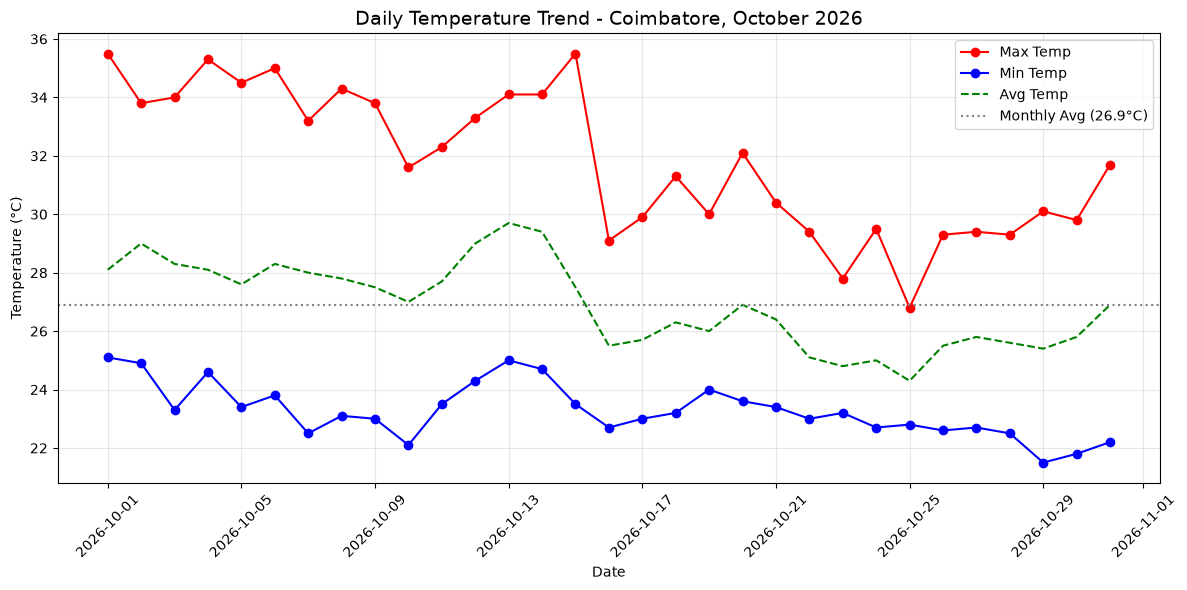

In [8]:
plt.figure(figsize=(12, 6))
plt.plot(df["Date"], df["Max_Temp"], color="red", marker="o", label="Max Temp")
plt.plot(df["Date"], df["Min_Temp"], color="blue", marker="o", label="Min Temp")
plt.plot(df["Date"], df["Avg_Temp"], color="green", linestyle="--", label="Avg Temp")
plt.axhline(y=average, color="gray", linestyle=":", label=f"Monthly Avg ({average:.1f}°C)")

plt.title("Daily Temperature Trend - Coimbatore, October 2026", fontsize=14)
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("graph1_temperature_trend.png", dpi=300)
plt.show()

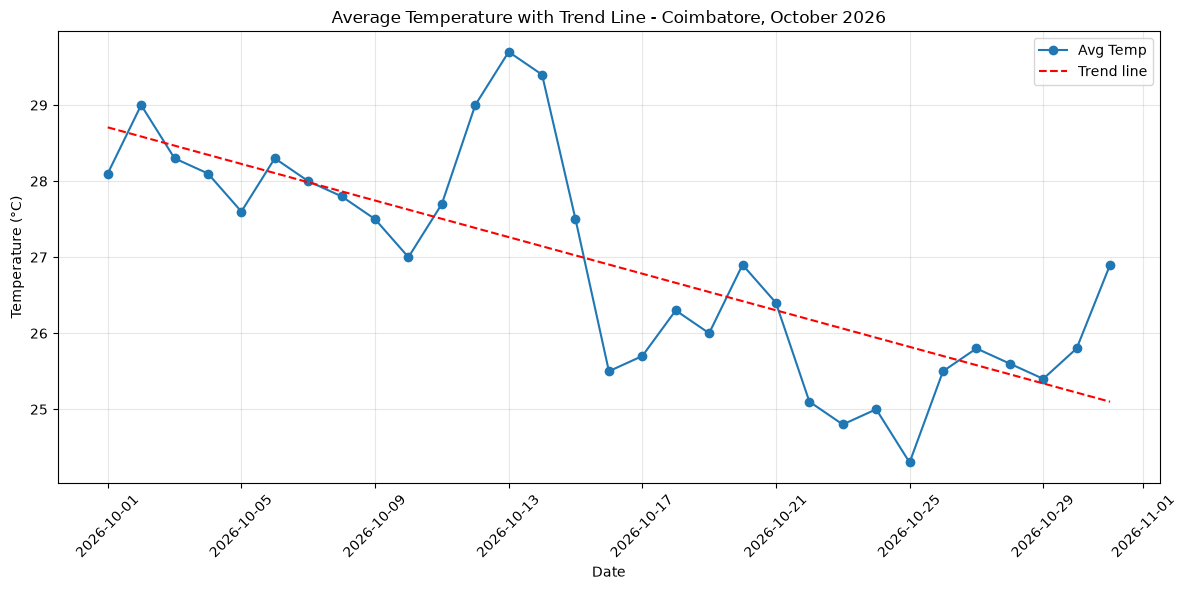

In [9]:
plt.figure(figsize=(12, 6))
plt.plot(df["Date"], df["Avg_Temp"], marker="o", label="Avg Temp")
plt.plot(df["Date"], slope * x + intercept, color="red", linestyle="--", label="Trend line")
plt.title("Average Temperature with Trend Line - Coimbatore, October 2026")
plt.xlabel("Date"); plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout()
plt.savefig("graph2_trend_line.png", dpi=300)
plt.show()

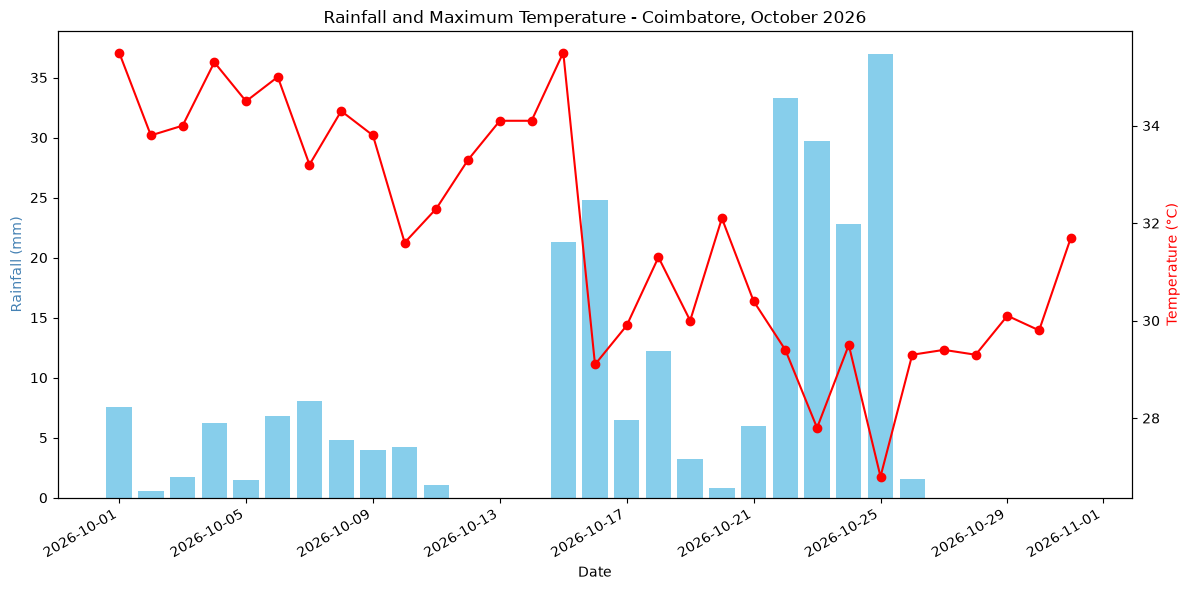

In [10]:
fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.bar(df["Date"], df["Rain_mm"], color="skyblue", label="Rainfall (mm)")
ax1.set_xlabel("Date")
ax1.set_ylabel("Rainfall (mm)", color="steelblue")

ax2 = ax1.twinx()
ax2.plot(df["Date"], df["Max_Temp"], color="red", marker="o", label="Max Temp")
ax2.set_ylabel("Temperature (°C)", color="red")

plt.title("Rainfall and Maximum Temperature - Coimbatore, October 2026")
fig.autofmt_xdate()
fig.tight_layout()
plt.savefig("graph3_rain_temp.png", dpi=300)
plt.show()

In [11]:
df.to_csv("cleaned_weather_data.csv", index=False)
print("Saved cleaned_weather_data.csv")

Saved cleaned_weather_data.csv
